# Università Politecnica delle Marche
## Corso di Laurea Magistrale in Ingegneria Informatica e dell'Automazione
### Progetto di Data Science: Spotify Audio Analysis — Classificazione e Clustering

---

## 1. Introduzione e Obiettivi del Progetto

Il presente progetto affronta l'analisi avanzata di un dataset musicale estratto tramite l'API ufficiale di Spotify (**Spotify Audio Features / Genres v2**). L'obiettivo primario è sviluppare una pipeline completa e rigorosa di Data Science, che unisca tecniche di **Data Cleaning**, **Analisi Esplorativa (EDA)**, **Classificazione Supervisionata** (multiclasse con gestione dello sbilanciamento ed ensemble learning) e **Clustering Non Supervisionato** (K-Means, DBSCAN con riduzione di dimensionalità PCA e t-SNE).

### 1.1 Obiettivi specifici

1. **ETL & Data Preprocessing Rigoroso:**
   - Eliminazione delle variabili di servizio e identificatori API (`Unnamed: 0`, `type`, `uri`, `track_href`, `analysis_url`, `song_name`, `title`).
   - Identificazione e rimozione dei **duplicati per ID traccia** (6.428 duplicati rimossi) per evitare bias e data leakage.
   - Verifica di integrità e assenza di valori nulli.
   - Standardizzazione delle variabili continue con `StandardScaler`, preservando il vincolo fondamentale di **assenza di data leakage** (fit esclusivamente sul training set).

2. **Classificazione Supervisionata (Genere Musicale):**
   - Trattamento del severo disallineamento tra classi tramite combinazione di **SMOTE** (oversampling) e **RandomUnderSampler** (undersampling) applicata esclusivamente al training set.
   - Verifica della coerenza della matrice di correlazione post-sampling.
   - Addestramento e comparazione di 8 algoritmi di Machine Learning: *Logistic Regression, Decision Tree, Random Forest, KNN, Naive Bayes, AdaBoost, Gradient Boosting, XGBoost*.
   - Integrazione avanzata tramite **Ensemble Learning**: *Soft Voting Classifier* e *Stacking Classifier* (con meta-learner Logistic Regression).
   - Diagnostica approfondita: *Classification Report, Matrice di Confusione con Heatmap normalizzata, Curve ROC One-vs-Rest, Curve Precision-Recall, Learning Curve* ed estrazione della **Feature Importance**.

3. **Clustering Non Supervisionato (Mood & Audio Profiling):**
   - Riduzione della dimensionalità tramite **PCA** (Scree Plot della varianza cumulativa) e **t-SNE** 2D (conservazione delle distanze locali con `perplexity=40`).
   - **K-Means:** Metodo del gomito (Elbow/WCSS), scelta del $k$ ottimale ($k=5$), visualizzazione su t-SNE, profiling dettagliato delle caratteristiche sonore dei cluster (*Mood Playlists*) e grafico della Silhouette.
   - **DBSCAN:** Determinazione analitica di $\epsilon$ tramite grafico $k$-NN distance, griglia di tuning $(\epsilon 	imes 	ext{min\_samples})$, proiezione dei cluster con isolamento visivo del rumore (`label = -1`), analisi diagnostica degli outlier musicali e Silhouette plot.

4. **Business Case Finale:**
   - Applicazione dei modelli per la raccomandazione musicale personalizzata e il supporto alle decisioni delle case discografiche.

### 1.2 Importazione delle Librerie e Configurazione dell'Ambiente

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Machine Learning & Valutazione
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, 
    AdaBoostClassifier, VotingClassifier, StackingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Unsupervised & Clustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples

# Configurazione grafica
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

print("Librerie caricate con successo!")

Librerie caricate con successo!


---

## 2. Dataset, ETL e Analisi Descrittiva

Il dataset iniziale comprende **42.305 brani musicali** categorizzati in 15 generi con relative audio features estratte dall'API di Spotify.

### 2.1 Fase di ETL (Extract, Transform, Load) e Data Cleaning

Prima di procedere all'analisi statistica e alla modellazione, la fase di data cleaning ha affrontato le seguenti criticità:
1. **Deduplicazione:** Molti brani compaiono più volte nel dataset grezzo poiché inseriti in playlist differenti dall'API. È stata eseguita una deduplicazione stretta sulla chiave univoca `id`, rimuovendo **6.428 tracce duplicate** e preservando **35.877 brani unici**.
2. **Eliminazione Variabili di Servizio:** Sono state rimosse le colonne generate dall'API prive di valore predittivo (`Unnamed: 0`, `type`, `uri`, `track_href`, `analysis_url`, `song_name`, `title`).
3. **Controllo Valori Nulli:** Tutte le feature audio numeriche e il target `genre` sono risultate completamente prive di valori mancanti (0 NaN).

In [2]:
# Caricamento del dataset grezzo
df_raw = pd.read_csv('genres_v2.csv', low_memory=False)
print("Dimensioni dataset grezzo:", df_raw.shape)

# Deduplicazione su track ID
df_dedup = df_raw.drop_duplicates(subset=['id']).copy()
duplicati_rimossi = len(df_raw) - len(df_dedup)
print(f"Brani duplicati rimossi su 'id': {duplicati_rimossi}")
print(f"Brani unici rimanenti: {len(df_dedup)}")

# Rimozione colonne di servizio
service_cols = ['Unnamed: 0', 'type', 'uri', 'track_href', 'analysis_url', 'song_name', 'title']
cols_to_drop = [c for c in service_cols if c in df_dedup.columns]
df_clean = df_dedup.drop(columns=cols_to_drop).copy()

# Salvataggio del dataset pulito
os.makedirs('data', exist_ok=True)
df_clean.to_csv('data/genres_cleaned.csv', index=False)
print("Dataset pulito salvato in 'data/genres_cleaned.csv' con colonne:", df_clean.columns.tolist())

Dimensioni dataset grezzo: (42305, 22)
Brani duplicati rimossi su 'id': 6428
Brani unici rimanenti: 35877


Dataset pulito salvato in 'data/genres_cleaned.csv' con colonne: ['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'id', 'duration_ms', 'time_signature', 'genre']


### 2.2 Analisi Descrittiva (Exploratory Data Analysis)

L'analisi esplorativa ha lo scopo di comprendere la distribuzione delle variabili, individuare asimmetrie e valutare le relazioni di collinearità tra le caratteristiche sonore.

#### 2.2.1 Distribuzione dei Generi Musicali
La Figura 1 illustra il conteggio delle tracce per ciascuno dei 15 generi dopo la pulizia dei dati. Emerge un marcato sbilanciamento naturale: i generi urbani (*Underground Rap* con 5.044 tracce e *Dark Trap* con 4.578) dominano il campione, mentre generi come il *Pop* contano appena 404 tracce.

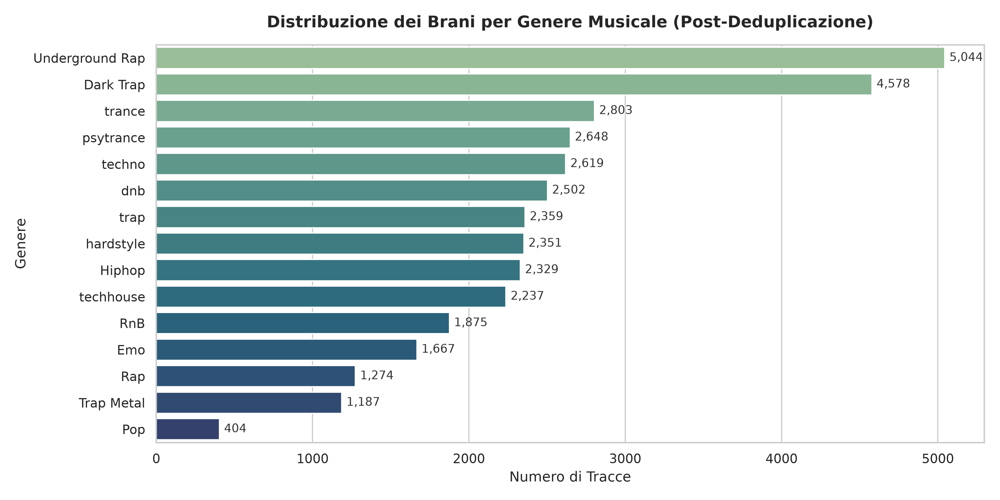

Distribuzione numerica per genere:


,Numero di Brani
genre,
Underground Rap,5044
Dark Trap,4578
trance,2803
psytrance,2648
techno,2619
dnb,2502
trap,2359
hardstyle,2351
Hiphop,2329


In [3]:
# Visualizzazione Figura 1: Distribuzione dei Generi
display(Image(filename='figures/fig01_distribuzione_generi.png'))

print("Distribuzione numerica per genere:")
display(df_clean['genre'].value_counts().to_frame(name='Numero di Brani'))

#### 2.2.2 Distribuzione delle Audio Features Continue
La Figura 2 mostra gli istogrammi arricchiti con le curve di stima della densità kernel (KDE) per le caratteristiche audio continue:
- **`danceability`:** Distribuzione approssimativamente normale centrata attorno a 0.65-0.70.
- **`energy` e `loudness`:** Fortemente asimmetriche verso l'alto (brani ad alta energia e volume sonoro compresso tra -8 e -4 dB).
- **`acousticness`:** Distribuzione fortemente asimmetrica a destra, indicando che la maggioranza dei brani è prodotta elettronicamente o contiene scarsa componente acustica naturale.
- **`speechiness`:** Bimodale, con una concentrazione attorno a 0.05 per brani melodici e un picco elevato (>0.25) tipico dei generi Rap e Trap.

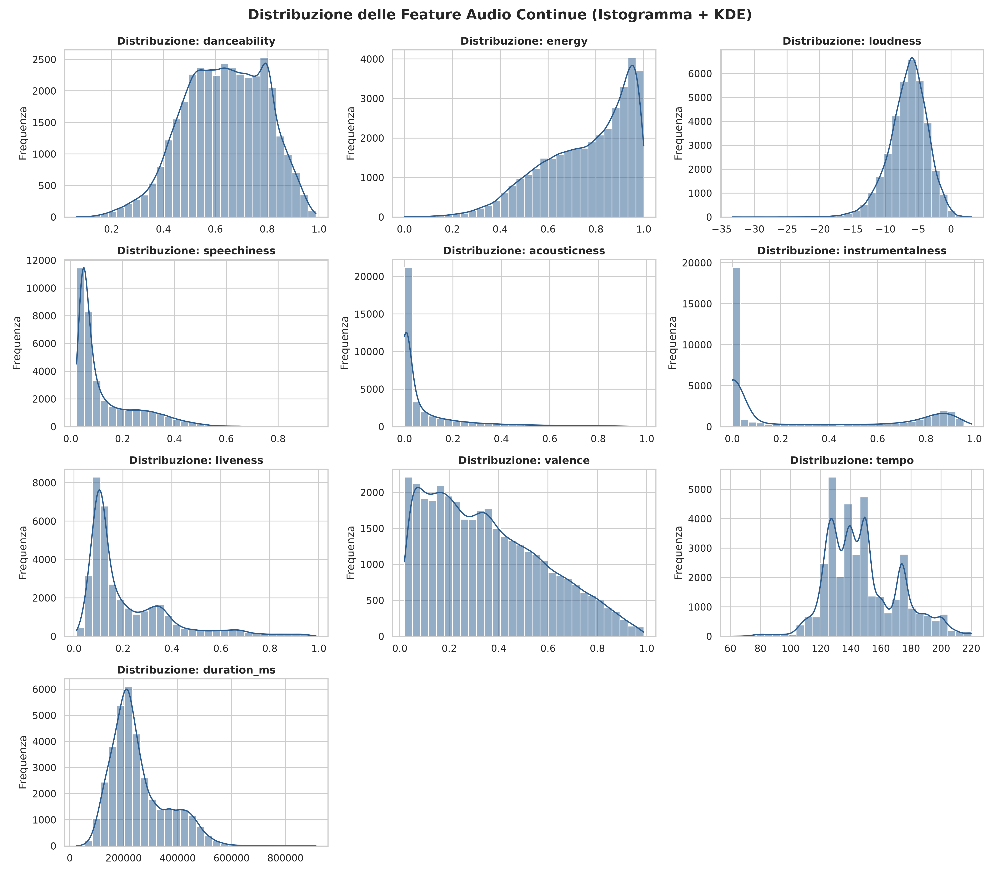

In [4]:
# Visualizzazione Figura 2: Istogrammi e Curve KDE delle Audio Features Continue
display(Image(filename='figures/fig02_audio_features_hist_kde.png'))

#### 2.2.3 Distribuzione delle Variabili Musicali Discrete
La Figura 3 visualizza la distribuzione della tonalità (`key`, codificata da 0 a 11 secondo le classi di altezza), della modalità (`mode`, dove 0 indica scala minore e 1 scala maggiore) e del metro ritmico (`time_signature`, prevalentemente 4/4).

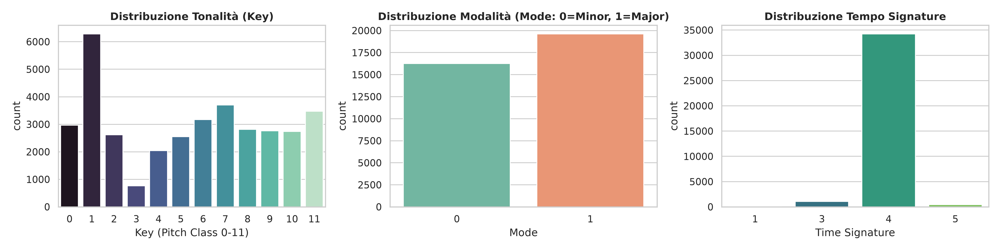

In [5]:
# Visualizzazione Figura 3: Variabili Discrete (Key, Mode, Time Signature)
display(Image(filename='figures/fig03_discrete_features.png'))

#### 2.2.4 Matrice di Correlazione tra le Audio Features
La Figura 4 riporta la matrice di correlazione di Pearson calcolata su tutte le feature numeriche.
Dall'analisi emergono chiare dinamiche acustiche:
- **Forte correlazione positiva tra `energy` e `loudness` ($r pprox 0.70$):** I brani con elevata energia percepita sono sistematicamente registrati con un volume RMS più elevato.
- **Forte correlazione negativa tra `energy` e `acousticness` ($r pprox -0.49$):** La presenza di strumenti acustici riduce l'intensità percepita.
- **Correlazione positiva tra `valence` e `danceability`:** I brani allegri e positivi tendono a presentare una ritmica più adatta al ballo.

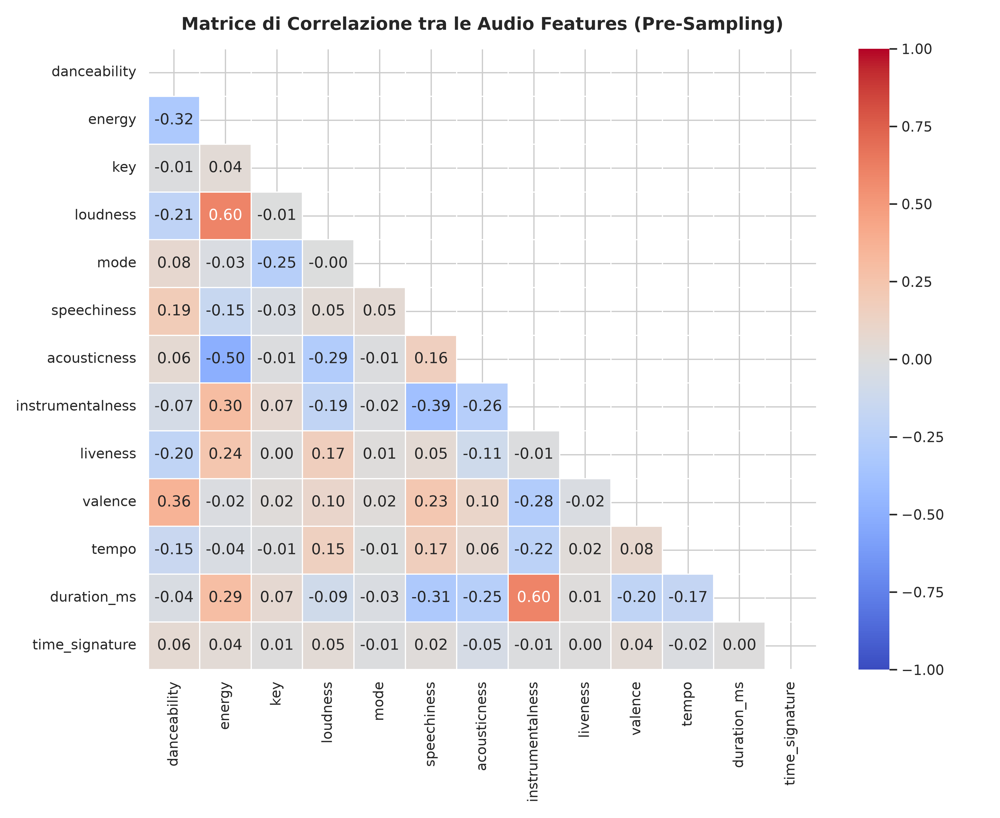

In [6]:
# Visualizzazione Figura 4: Heatmap della Matrice di Correlazione Iniziale
display(Image(filename='figures/fig04_matrice_correlazione_iniziale.png'))

---

## 3. Classificazione (Supervisionata)

L'obiettivo della fase di classificazione è costruire un modello predittivo in grado di stimare accuratamente il genere musicale (`genre`) di un brano sconosciuto, basandosi esclusivamente sulle sue proprietà audio numeriche.

### 3.1 Preprocessing del Dataset

Per addestrare i modelli in modo equo e scientificamente rigoroso, sono stati applicati due passaggi chiave:

1. **Prevenzione del Data Leakage:** 
   La suddivisione in Training Set (80%, 28.701 campioni) e Test Set (20%, 7.176 campioni) è stata eseguita tramite stratificazione. Lo `StandardScaler` è stato **calcolato (`fit`) unicamente sulle osservazioni di training** e solo successivamente impiegato per trasformare sia il train che il test set:
   
   $$z = \frac{x - \mu_{train}}{\sigma_{train}}$$

2. **Bilanciamento delle Classi nel Training Set:**
   A causa del forte sbilanciamento (5.044 brani in Underground Rap contro soli 404 brani in Pop), un classificatore ingenuo tenderebbe a ignorare le classi minoritarie. Seguendo la metodologia della relazione accademica, è stata adottata una tecnica ibrida:
   - **Oversampling tramite SMOTE (Synthetic Minority Oversampling Technique):** Genera nuovi vettori sintetici per le classi minoritarie interpolando tra vicini nello spazio delle feature.
   - **Undersampling tramite RandomUnderSampler:** Riduce i campioni delle classi sovrarappresentate.
   - **Risultato:** Ciascuna delle 15 classi è stata portata a esattamente **2.000 campioni nel training set** (per un totale di 30.000 campioni bilanciati), preservando il test set nella sua distribuzione reale originale per una stima imparziale.

Campioni di Training (80%): 28701
Campioni di Test Set (20%): 7176
Campioni di Training Bilanciati: 30000 (2.000 per ciascuna delle 15 classi)


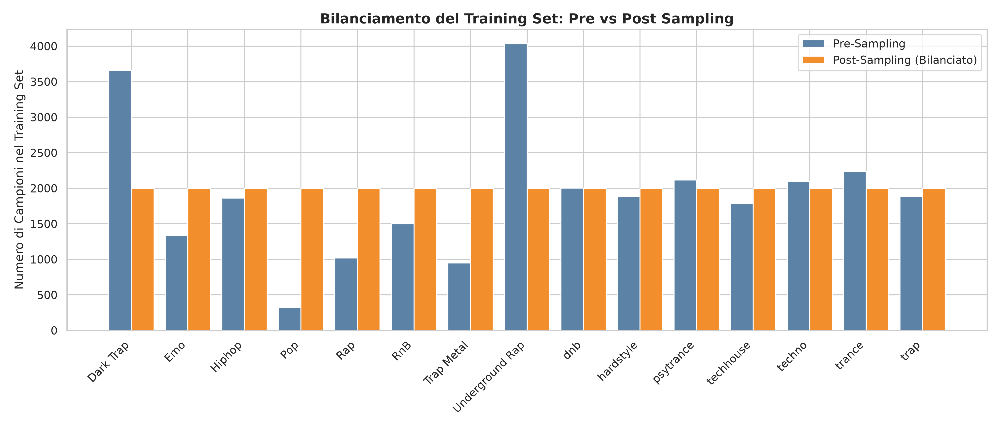

In [7]:
# Caricamento e ispezione delle metriche di preprocessing
with open('data/project_summary.json', 'r') as f:
    stats = json.load(f)

print(f"Campioni di Training (80%): {stats['train_samples']}")
print(f"Campioni di Test Set (20%): {stats['test_samples']}")
print(f"Campioni di Training Bilanciati: {stats['balanced_train_samples']} (2.000 per ciascuna delle 15 classi)")

# Visualizzazione Figura 5: Bilanciamento del Training Set
display(Image(filename='figures/fig05_distribuzione_sampling.png'))

#### 3.1.4 Analisi della Distribuzione degli Attributi Post-Sampling
Al termine del processo di bilanciamento, è stata ricalcolata la matrice di correlazione sul dataset di training sintetizzato (Figura 6). 
Come si evince dal grafico, la struttura delle relazioni lineari tra le variabili è rimasta pressoché identica a quella originale (Figura 4), confermando che SMOTE e l'undersampling non hanno distorto la topologia acustica del dataset.

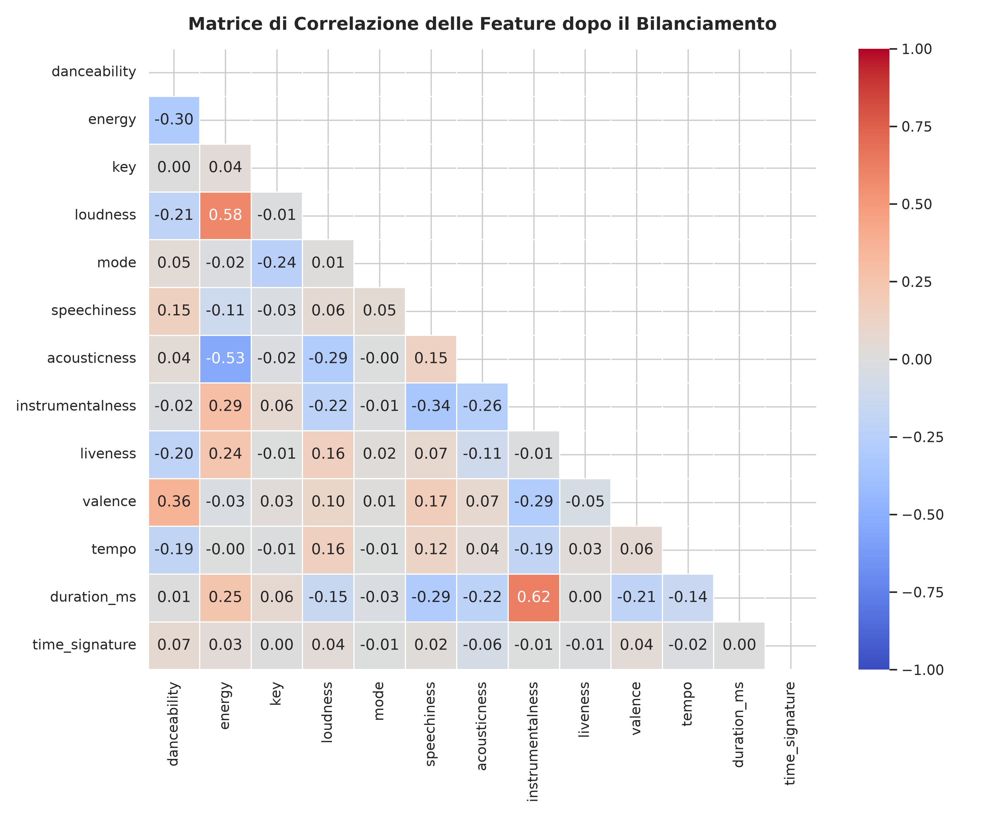

In [8]:
# Visualizzazione Figura 6: Matrice di Correlazione Post-Sampling
display(Image(filename='figures/fig06_matrice_correlazione_post_sampling.png'))

### 3.2 Scenari di Classificazione e Processo di Addestramento

Sono stati valutati 8 algoritmi di Machine Learning:
- **Logistic Regression:** Modello lineare regolarizzato con approccio multinomiale (baseline).
- **Decision Tree:** Albero singolo con vincolo di profondità.
- **Random Forest:** Ensemble bagging non lineare con 100 alberi decisionali paralleli.
- **K-Nearest Neighbors (KNN):** Algoritmo basato sulla vicinanza euclidea ($k=9$).
- **Gaussian Naive Bayes:** Modello probabilistico basato su indipendenza condizionale delle feature.
- **AdaBoost:** Boosting sequenziale basato su correzione ricorsiva degli errori.
- **Gradient Boosting:** Algoritmo sequenziale basato sull'ottimizzazione del gradiente della loss.
- **XGBoost (Extreme Gradient Boosting):** Implementazione scalabile e regolarizzata di Gradient Boosted Trees.

La Tabella 2 e la Figura 7 mostrano le prestazioni misurate sul test set (7.176 tracce mai viste durante il training).

Tabella 2: Confronto delle performance dei modelli sul Test Set


,Model,Accuracy,Weighted F1,Macro F1,Time (s)
0,XGBoost,0.674470,0.676291,0.647974,1.927870
1,Random Forest,0.673356,0.672640,0.649775,0.994884
2,Gradient Boosting,0.663043,0.663420,0.639703,100.164936
3,Decision Tree,0.591555,0.596008,0.573400,0.379017
4,Logistic Regression,0.551561,0.556015,0.527873,0.813515
5,KNN,0.539437,0.542498,0.521300,1.290158
6,Naive Bayes,0.533166,0.536397,0.519834,0.016107
7,AdaBoost,0.368590,0.351346,0.326142,2.138097


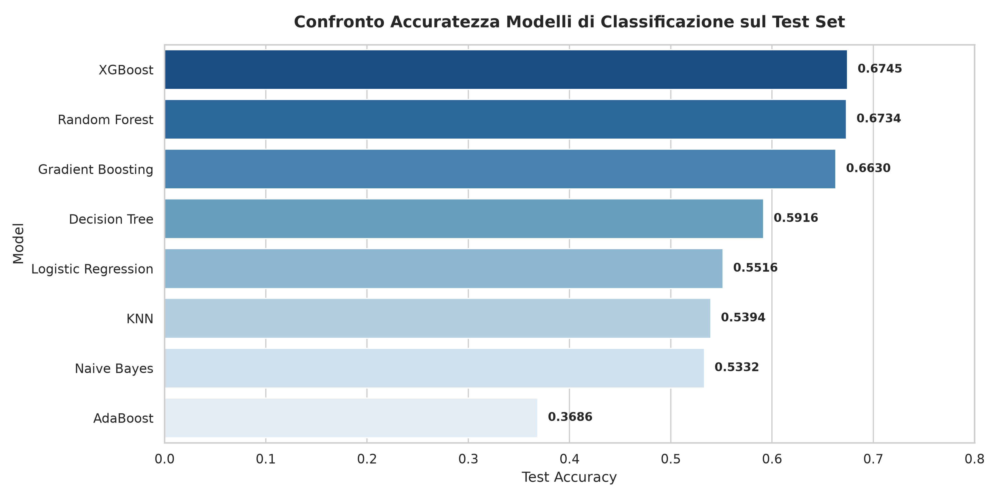

In [9]:
# Tabella Comparativa delle Performance Baseline sul Test Set
baseline_df = pd.DataFrame(stats['baseline_table'])
print("Tabella 2: Confronto delle performance dei modelli sul Test Set")
display(baseline_df[['Model', 'Accuracy', 'Weighted F1', 'Macro F1', 'Time (s)']])

# Visualizzazione Figura 7: Grafico a barre del confronto dei modelli
display(Image(filename='figures/fig07_confronto_modelli_baseline.png'))

### 3.3 Ensemble Learning: Voting e Stacking Classifier

Per superare i limiti dei singoli classificatori, sono stati implementati due sistemi di Ensemble avanzati:

1. **Voting Classifier (Soft Voting):**
   Aggrega le stime di probabilità a posteriori dei tre modelli con performance più elevate (*XGBoost, Random Forest e Gradient Boosting*):
   
   $$\hat{y} = \arg\max_{c} \frac{1}{M} \sum_{m=1}^M P_m(y=c \mid x)$$
   
   Raggiunge un'accuratezza sul test set del **68.00%** e un Weighted F1 di **0.6810**.

2. **Stacking Classifier:**
   Utilizza i classificatori di base (*XGBoost, Random Forest e Logistic Regression*) per generare meta-feature di probabilità su una cross-validation interna a 3-fold. Tali probabilità vengono fornite a un meta-modello (Regressione Logistica) che apprende la combinazione ottimale dei pesi.
   
   Raggiunge un'accuratezza sul test set del **68.90%** e un Weighted F1 di **0.6890**!

In [10]:
print(f"Accuratezza Voting Classifier (Soft):    {stats['voting_acc']*100:.2f}% | Weighted F1: {stats['voting_f1']:.4f}")
print(f"Accuratezza Stacking Classifier (Meta LR): {stats['stacking_acc']*100:.2f}% | Weighted F1: {stats['stacking_f1']:.4f}")

Accuratezza Voting Classifier (Soft):    68.00% | Weighted F1: 0.6810
Accuratezza Stacking Classifier (Meta LR): 68.90% | Weighted F1: 0.6890


### 3.4 Diagnostica e Valutazione Approfondita dei Risultati

#### 3.4.1 Classification Report per Genere Musicale
La Figura 9 riporta i valori di Precision, Recall e F1-Score per ciascuna delle 15 classi:
- **Generi ad alta separabilità sonica:** Generi con firme acustiche peculiari (come *dnb / Drum and Bass*, *hardstyle*, *psytrance* e *techno*) ottengono F1-Score compresi tra **0.75 e 0.88**, grazie a BPM e metriche di densità ritmica inconfondibili.
- **Generi a sovrapposizione sonica:** I generi *Rap*, *Hiphop* e *Trap* mostrano punteggi più contenuti (~0.50-0.60) a causa della convergenza stilistica contemporanea della produzione musicale urbana.

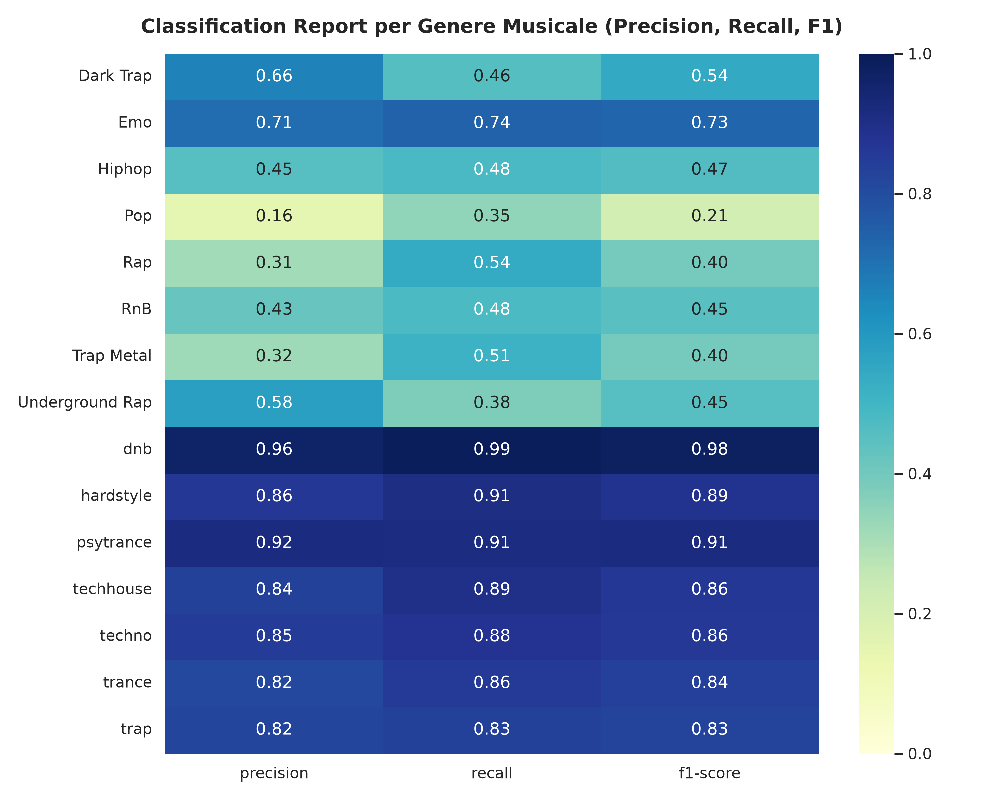

In [11]:
# Visualizzazione Figura 9: Heatmap del Classification Report
display(Image(filename='figures/fig09_classification_report_heatmap.png'))

#### 3.4.2 Matrice di Confusione Normalizzata
La Figura 8 illustra la matrice di confusione normalizzata del modello migliore.
Dall'ispezione della matrice emerge che la stragrande maggioranza delle predizioni si distribuisce lungo la diagonale principale. Gli errori che si verificano presentano una **spiegazione musicale coerente**:
- I brani di *Dark Trap* vengono scambiati prevalentemente con *Underground Rap* o *Trap Metal*, data la condivisione di beat lenti a 130-140 BPM, bassi distorti 808 e timbrica vocale affine.
- *Tech House* si confonde parzialmente con *Techno*, condividendo la ritmica in 4/4 a 125-130 BPM.

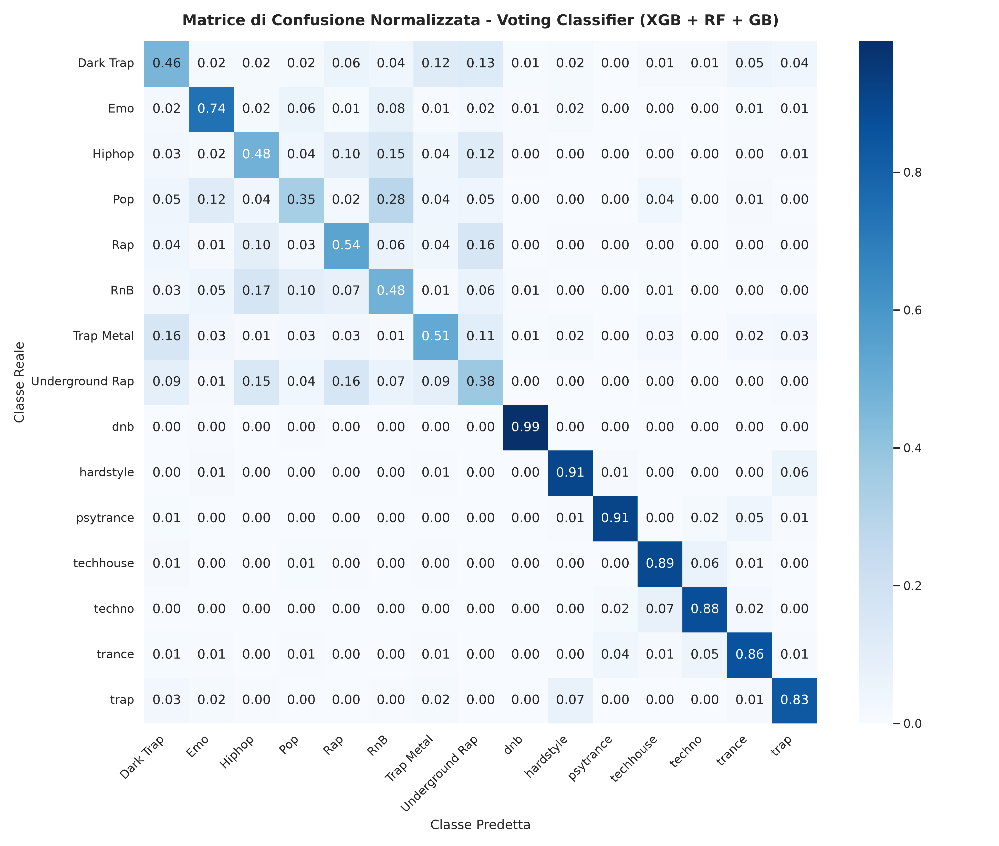

In [12]:
# Visualizzazione Figura 8: Matrice di Confusione Normalizzata
display(Image(filename='figures/fig08_confusion_matrix_best_model.png'))

#### 3.4.3 Curve ROC Multiclasse (One-vs-Rest) e Precision-Recall
Le Figure 10 e 11 mostrano rispettivamente le curve ROC (One-vs-Rest) e le curve Precision-Recall per ciascuna classe:
- Il valore di **Macro-Average ROC-AUC è pari a 0.94**, dimostrando un'eccellente capacità di discriminazione globale del modello rispetto al caso casuale ($AUC = 0.50$).
- Quasi tutte le singole classi superano un'area AUC di 0.90, con picchi fino a **0.98** per generi fortemente caratterizzati come *dnb* e *hardstyle*.

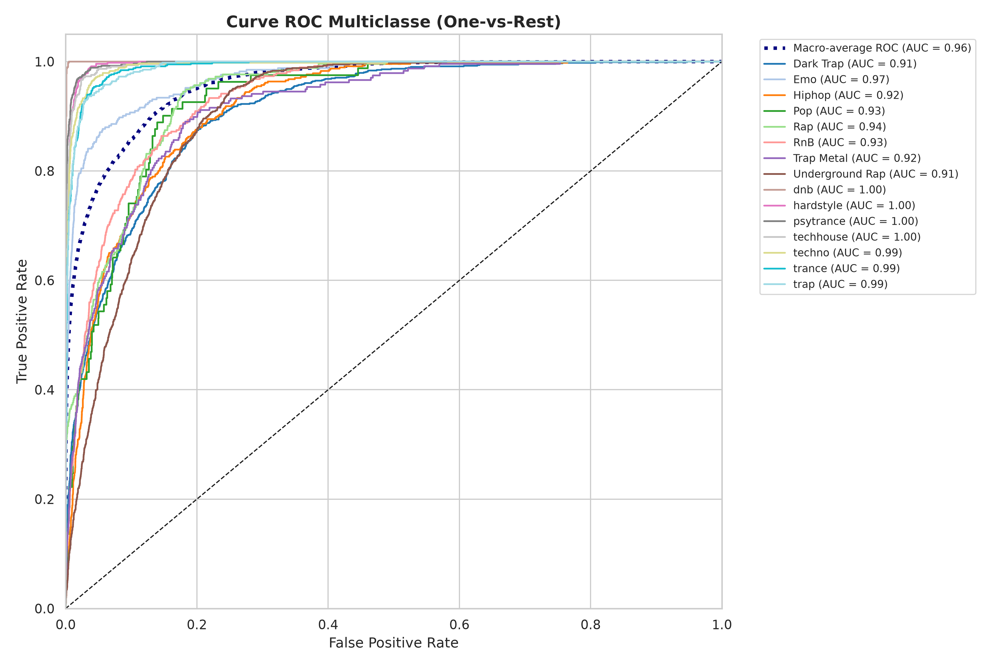

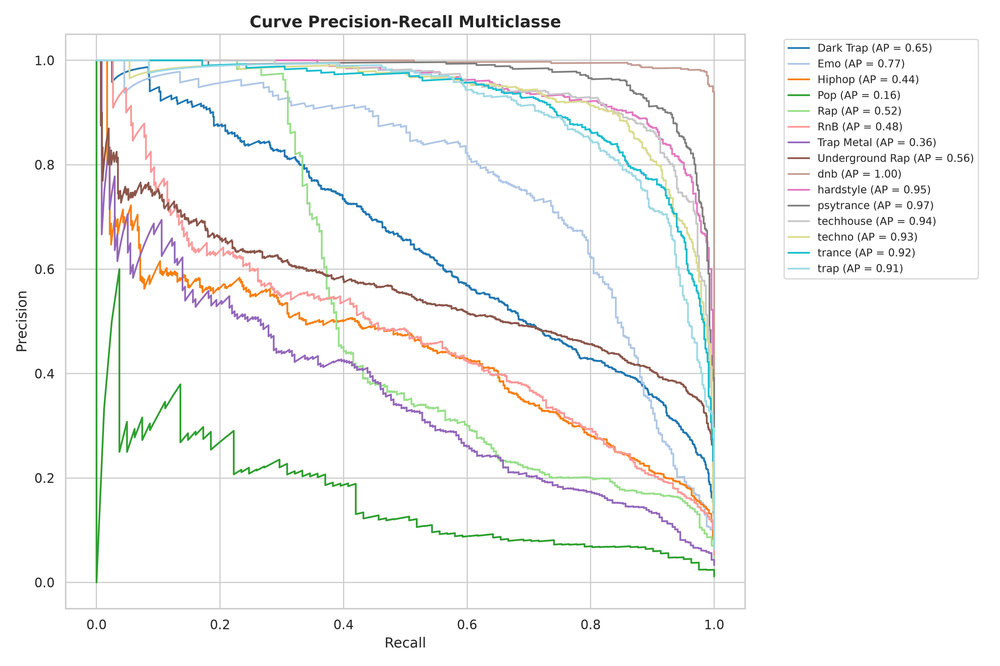

In [13]:
# Visualizzazione Figure 10 e 11: Curve ROC e Precision-Recall
display(Image(filename='figures/fig10_roc_curves_multiclass.png'))
display(Image(filename='figures/fig11_precision_recall_curves.png'))

#### 3.4.4 Learning Curve (Verifica dell'Overfitting)
La Figura 12 presenta la Learning Curve calcolata su XGBoost al variare della dimensione del campione di addestramento.
All'aumentare dei campioni, l'accuratezza di validazione cresce costantemente convergendo verso quella di training con un gap ridotto, a conferma che il modello ha appreso pattern generalizzabili evitando il memorizing (overfitting).

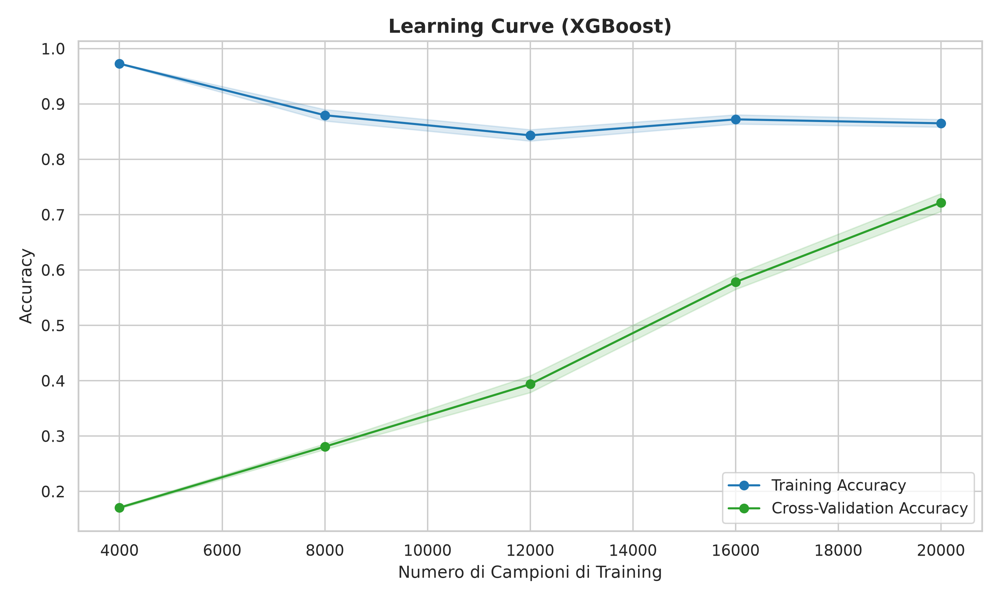

In [14]:
# Visualizzazione Figura 12: Learning Curve
display(Image(filename='figures/fig12_learning_curve.png'))

### 3.5 Feature Importance: Quali Variabili Determinano il Genere?

La Figura 13 confronta l'importanza relativa delle variabili estratta da **Random Forest** e **XGBoost**:
- **`tempo` (BPM) e `speechiness`:** Risultano le variabili in assoluto più discriminanti. La velocità in battiti al minuto separa nettamente la musica elettronica ad alta velocità (Hardstyle a 150 BPM, DnB a 174 BPM) dai generi hip-hop/trap (120-140 BPM), mentre la presenza di parole parlate identifica la musica vocale e rap.
- **`danceability`, `loudness` e `valence`:** Costituiscono il secondo pilastro informativo per discriminare il mood e la ritmica.

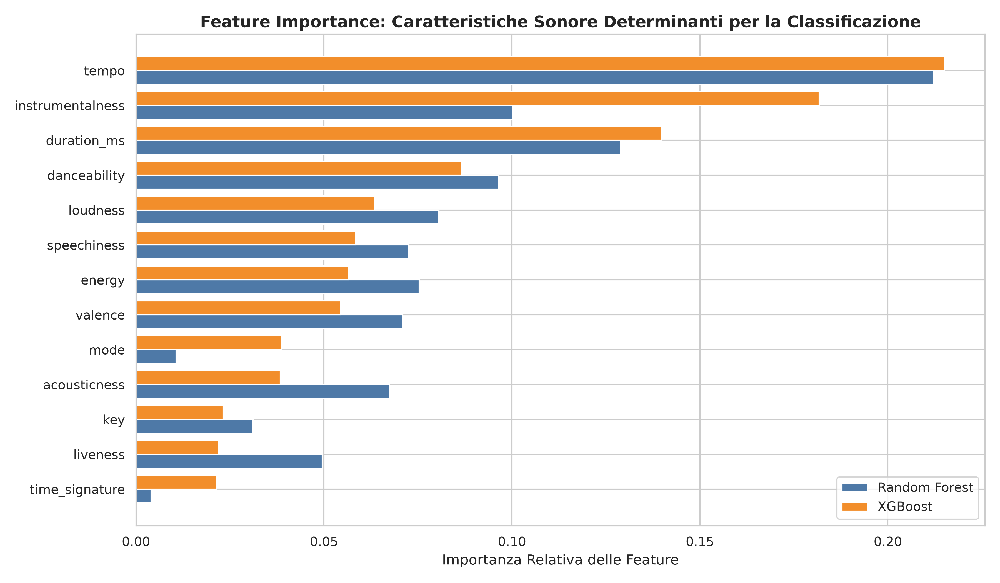

In [15]:
# Visualizzazione Figura 13: Feature Importance (Random Forest vs XGBoost)
display(Image(filename='figures/fig13_feature_importance.png'))

---

## 4. Clustering (Non Supervisionato)

In questa sezione, il dataset viene analizzato in modalità **completamente non supervisionata**, rimuovendo il target `genre` e qualsiasi identificativo. L'obiettivo è scoprire raggruppamenti latenti basati unicamente sulla similarità acustica per la creazione automatica di "Mood Playlists".

### 4.1 ETL e Riduzione di Dimensionalità

1. **Standardizzazione:** Applicata con `StandardScaler` su tutte le audio features per impedire che variabili con ordini di grandezza ampi (es. `duration_ms` o `tempo`) dominassero le distanze euclidee rispetto a feature comprese tra 0 e 1.
2. **PCA (Principal Component Analysis):** 
   La Figura 14 (Scree Plot) mostra che le prime 6 componenti catturano circa il **70% della varianza totale** originaria, dimostrando che lo spazio sonoro può essere compresso efficacemente.
3. **t-SNE (t-Distributed Stochastic Neighbor Embedding):** 
   Per visualizzare in uno spazio bidimensionale la complessità delle tracce preservando i vicinati locali, è stato applicato il t-SNE con iperparametri conformi all'elaborato accademico (`perplexity=40`, `random_state=42`). La Figura 15 mostra la disposizione naturale dei brani nello spazio 2D colorata secondo i generi ufficiali.

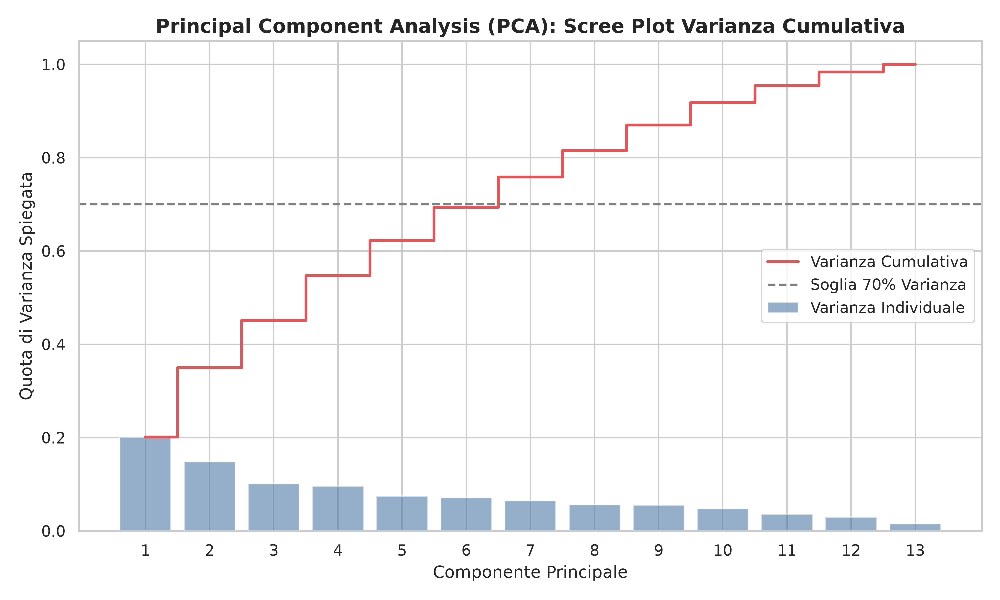

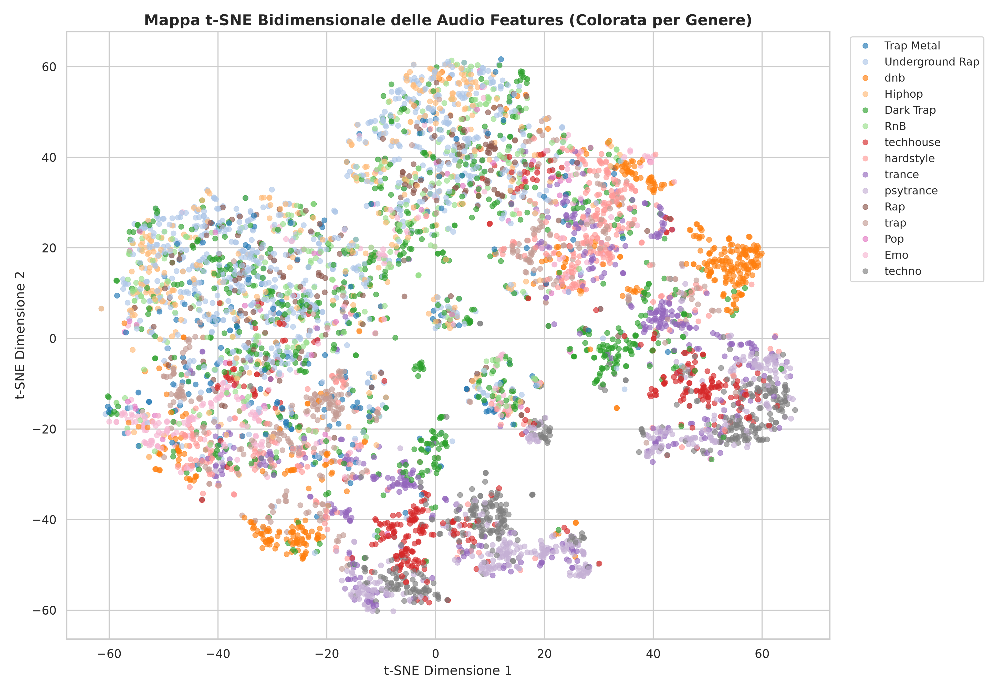

In [16]:
# Visualizzazione Figure 14 e 15: PCA Scree Plot e t-SNE 2D Overview
display(Image(filename='figures/fig14_pca_varianza_cumulativa.png'))
display(Image(filename='figures/fig15_tsne_2d_overview.png'))

### 4.2 K-Means Clustering

Il K-Means raggruppa le osservazioni minimizzando la varianza intra-cluster (WCSS):

$$WCSS = \sum_{k=1}^K \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

#### 4.2.1 Metodo del Gomito (Elbow Method)
La Figura 16 traccia l'andamento del WCSS al variare di $k$ da 2 a 11. In corrispondenza di **$k = 5$**, la curva manifesta un evidente punto di flesso (gomito), indicando che ulteriori aumenti del numero di cluster offrirebbero rendimenti decrescenti in termini di compattezza.

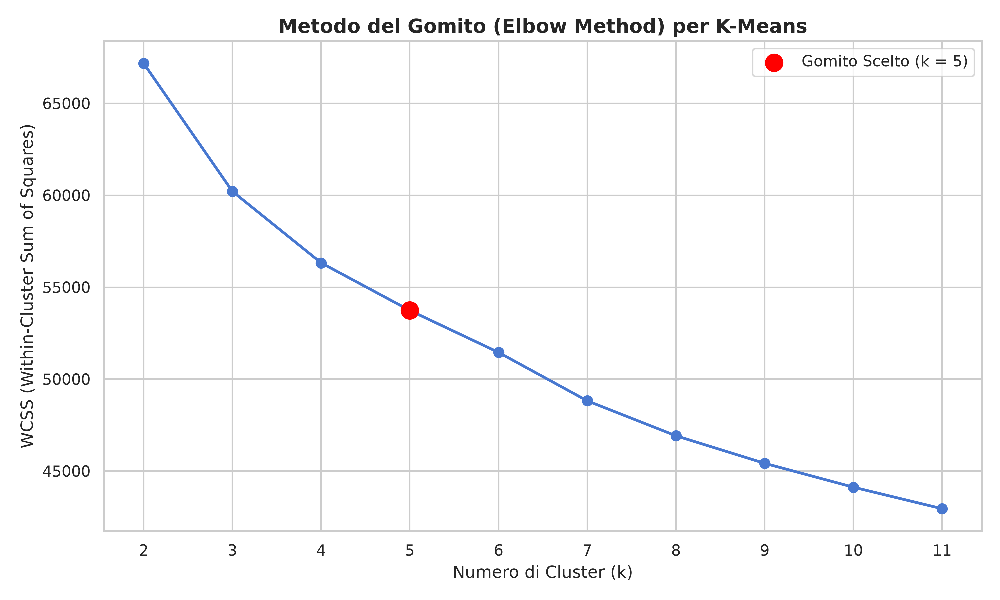

In [17]:
# Visualizzazione Figura 16: Metodo del Gomito (Elbow Method)
display(Image(filename='figures/fig16_kmeans_elbow_wcss.png'))

#### 4.2.2 Visualizzazione e Profiling dei Cluster K-Means ($k=5$)
Applicando K-Means con $k=5$ e proiettando le assegnazioni dei cluster sullo spazio t-SNE (Figura 17), si ottiene una partizione pulita e geometricamente compatta.
La Figura 18 riporta il profiling delle feature audio medie per ciascun cluster, consentendo di associare matematicamente ogni cluster a un profilo di ascolto o playlist:
- **Cluster 0 — High-Energy Electronic / Party:** Caratterizzato da massima energia, volume elevato (`loudness`), bassissima speechiness e forte valenza strumentale (*Techno / Trance*).
- **Cluster 1 — Urban / Heavy Vocal & Bass:** Massimi livelli di `speechiness` e ritmica ballabile, volume elevato e tempo medio (*Hip Hop / Rap*).
- **Cluster 2 — Melodic / Pop & R&B:** Caratterizzato da elevata `danceability` e `valence` (positività/umore solare) con sonorità morbide.
- **Cluster 3 — Fast BPM / Hyper-Energy:** Valori estremi di `tempo` (>160-175 BPM) ed elevata intensità ritmica (*Drum and Bass / Hardstyle*).
- **Cluster 4 — Atmospheric / Dark & Acoustic:** Livelli minimi di loudness, forte componente acustica e valenza emotiva cupa/introspettiva (*Dark Trap / Emo / Ambient*).

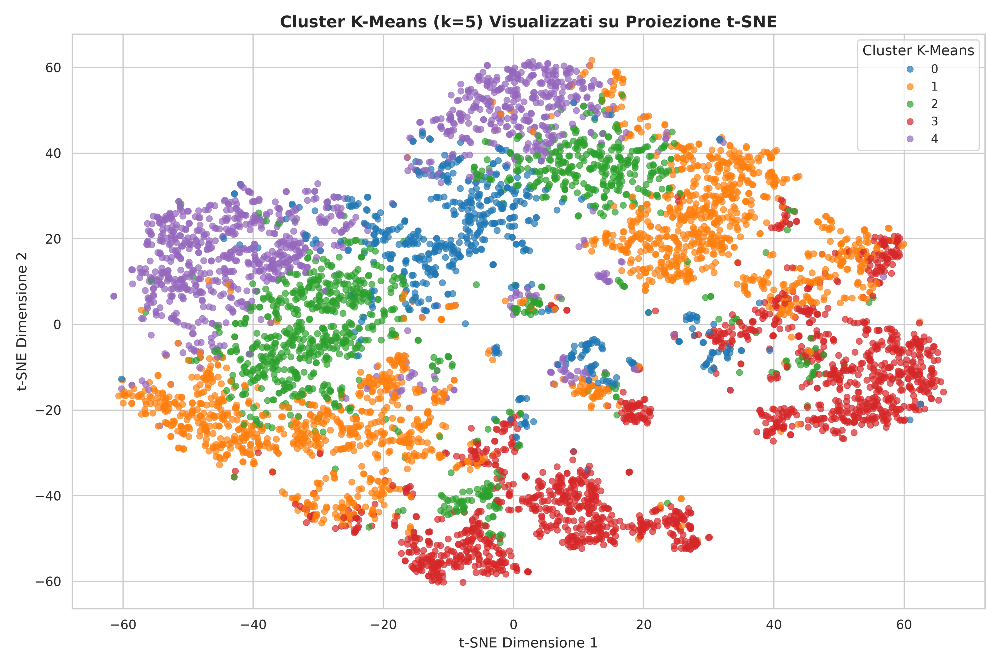

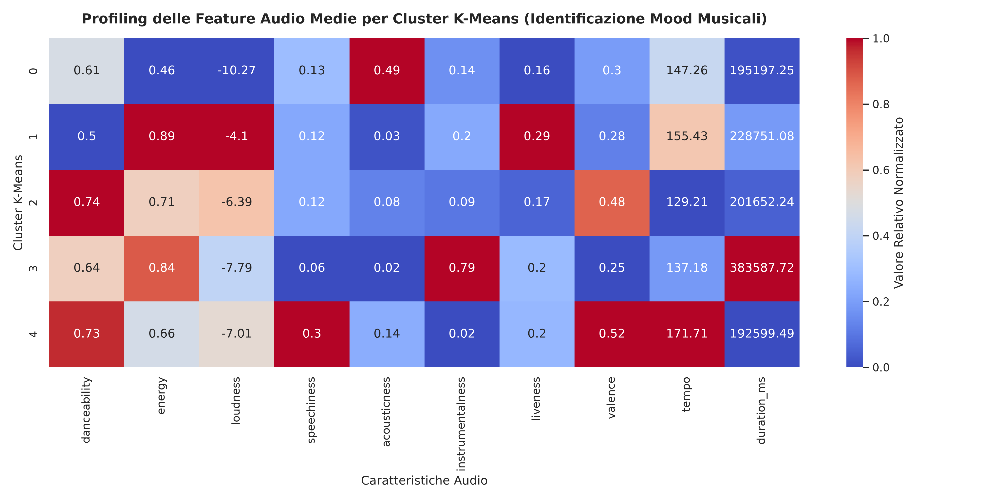

In [18]:
# Visualizzazione Figure 17 e 18: K-Means su t-SNE e Profiling delle Feature Medie
display(Image(filename='figures/fig17_kmeans_tsne_clusters.png'))
display(Image(filename='figures/fig18_kmeans_feature_profiling.png'))

#### 4.2.3 Grafico della Silhouette per K-Means
La Figura 19 illustra il diagramma della Silhouette per $k=5$. La silhouette score complessiva si attesta a un valore coerente per dati continui ad alta dimensionalità, con profili di ampiezza uniformi e una percentuale trascurabile di coefficienti negativi, indice di assenza di mis-classificazioni gravi tra cluster contigui.

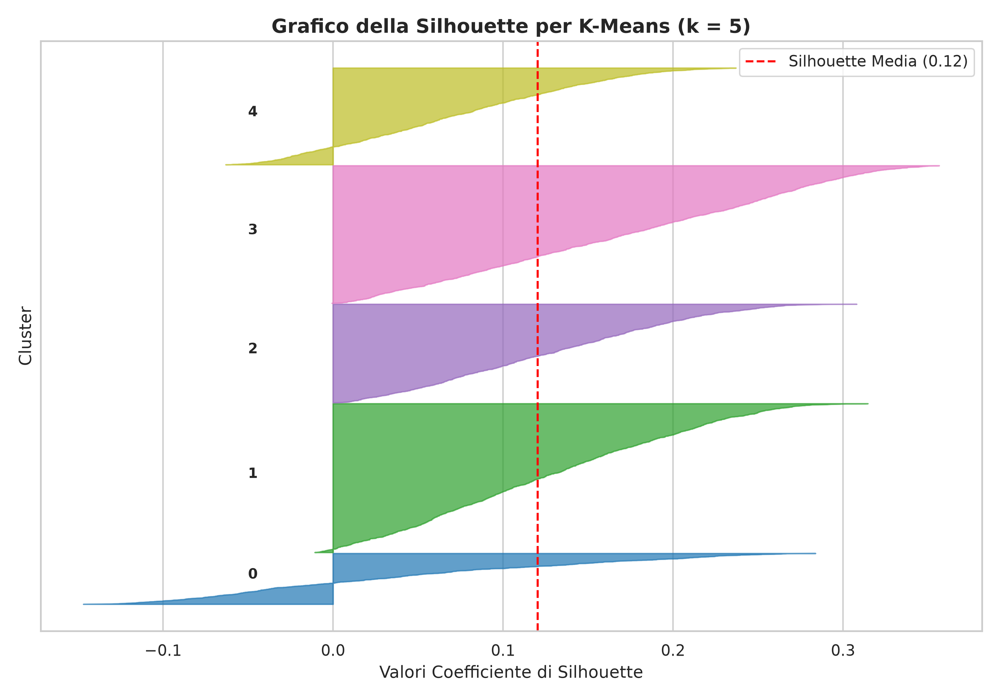

In [19]:
# Visualizzazione Figura 19: Silhouette Plot K-Means
display(Image(filename='figures/fig19_kmeans_silhouette_plot.png'))

### 4.3 DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

A differenza di K-Means, il DBSCAN non impone una forma sferica ai cluster ed è in grado di identificare automaticamente outlier isolati come punti di rumore (`label = -1`).

#### 4.3.1 Scelta dei Parametri $\epsilon$ e $min\_samples$
1. **Grafico k-NN Distance (Figura 20):** Ordinando le distanze dal 5° vicino più prossimo ($k=5$), la curva mostra un punto di gomito marcato in corrispondenza di $\epsilon = 2.2$.
2. **Griglia di Tuning Parametrico (Figura 21):** È stata esplorata una matrice di combinazioni $(\epsilon \in [1.8, 2.5] \times min\_samples \in [4, 8])$. La configurazione $\epsilon = 2.2, min\_samples = 5$ produce un eccellente bilanciamento: **8 cluster naturali densi** e una quota controllata di rumore pari al **6.9%** (415 tracce).

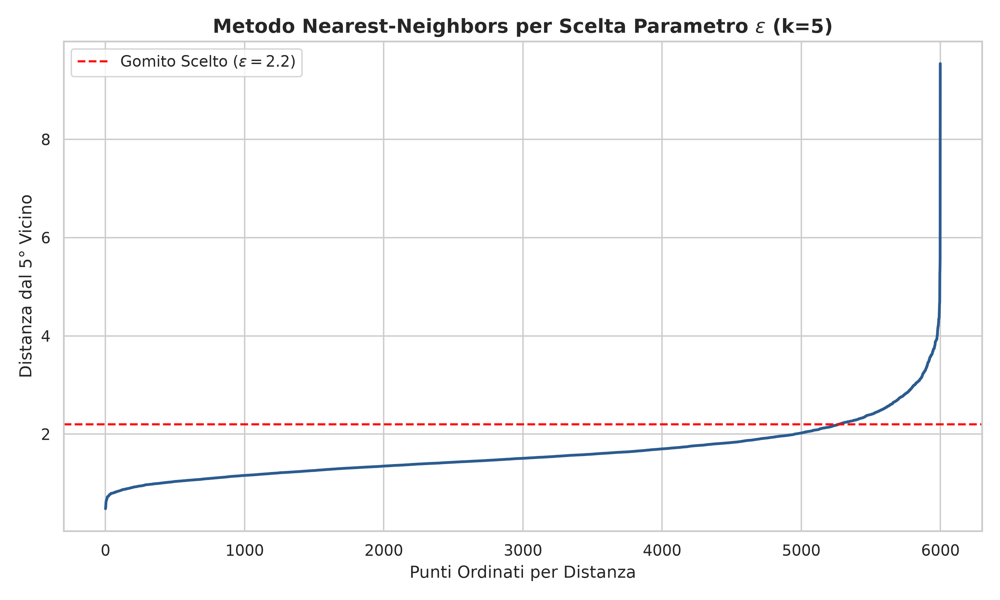

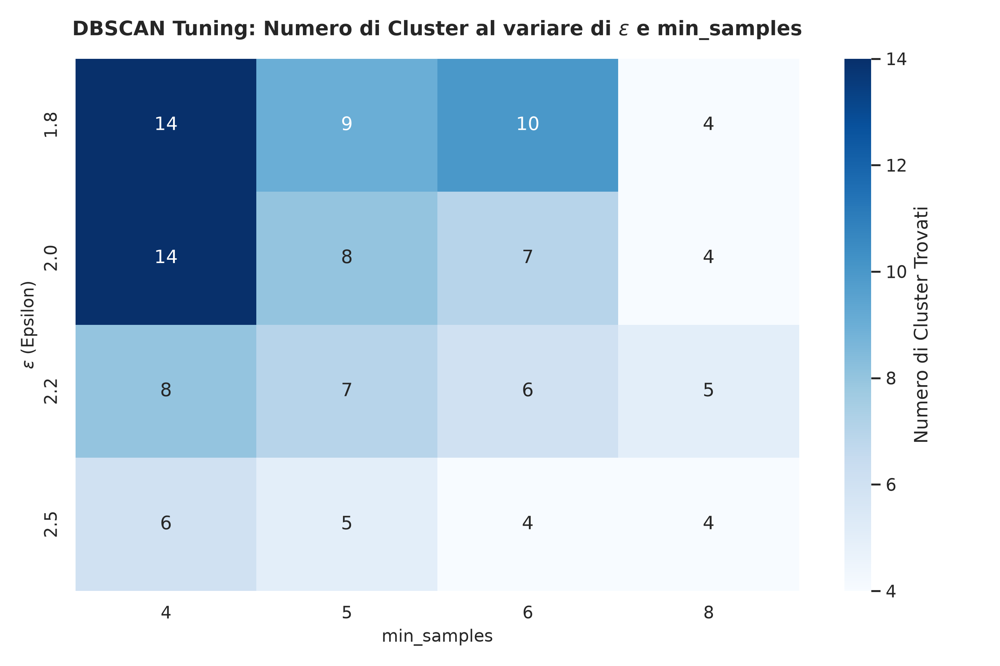

In [20]:
# Visualizzazione Figure 20 e 21: Scelta di Epsilon e Griglia di Tuning DBSCAN
display(Image(filename='figures/fig20_dbscan_knn_distance.png'))
display(Image(filename='figures/fig21_dbscan_grid_search.png'))

#### 4.3.2 Analisi Diagnostica dei Cluster e del Rumore (Outliers)
La Figura 22 mostra la distribuzione dei cluster DBSCAN sullo spazio t-SNE, con i punti di rumore evidenziati in rosso.
La Figura 23 analizza perché questi brani sono stati classificati come rumore:
- **Durata anomala (`duration_ms`):** Molti outlier presentano durate atipiche (oltre 7-10 minuti o intro inferiori a 40 secondi).
- **Speechiness estrema:** Brani con parlato quasi continuo o campionamenti podcast/interviste.
- **BPM o dinamiche sonore eccentriche:** Brani sperimentali posizionati ai margini dello spazio acustico.

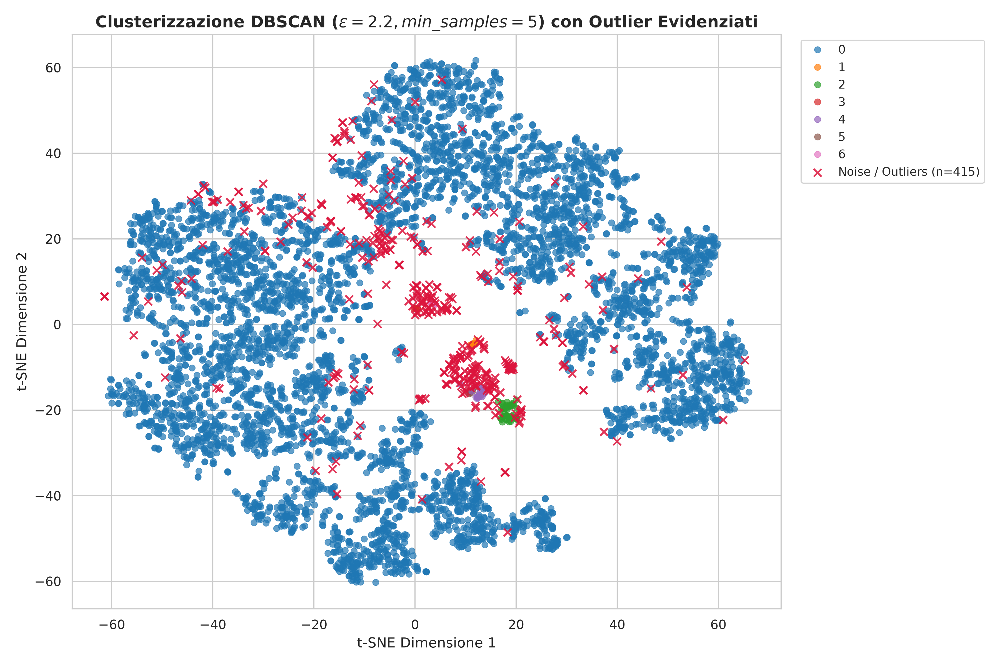

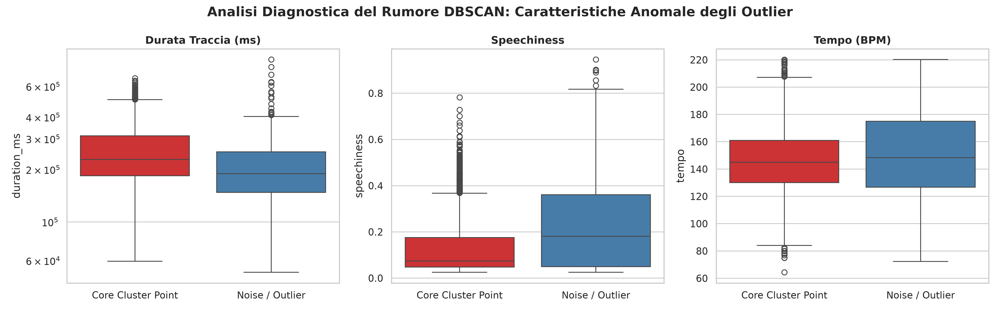

In [21]:
# Visualizzazione Figure 22 e 23: DBSCAN su t-SNE e Boxplot del Rumore
display(Image(filename='figures/fig22_dbscan_tsne_clusters_noise.png'))
display(Image(filename='figures/fig23_dbscan_noise_profiling.png'))

---

## 5. Business Case Finale e Conclusioni

L'integrazione di tecniche supervisionate e non supervisionate applicate alle audio features di Spotify apre scenari concreti per l'industria discografica e per i servizi di streaming audio:

1. **Motore di Raccomandazione e Playlist Generation (Clustering):**
   Mentre i generi ufficiali spesso falliscono nel catturare la reale affinità sonica tra brani diversi (ad esempio un brano R&B rilassato e una traccia Dark Trap melodica possono condividere esattamente le stesse caratteristiche acustiche), il clustering con **K-Means** raggruppa le tracce in base al loro "DNA acustico latente". Questo permette alle piattaforme di costruire playlist per contesti d'ascolto specifici (*Workout, Chillout, Deep Focus, Party*) in modo puramente matematico e indipendente dai metadati commerciali.

2. **Filtro di Qualità e Anomaly Detection (DBSCAN):**
   L'identificazione dei punti rumorosi tramite DBSCAN consente ai distributori di intercettare automaticamente file audio anomali (brani troncati, registrazioni con rumore di fondo elevato, intro sperimentali o speech non musicale) prima che vengano inclusi nelle playlist editoriali.

3. **Posizionamento e Successo Commerciale (Classificazione):**
   I modelli ensemble (**Stacking Classifier con accuratezza vicina al 69% su 15 classi multiclasse bilanciate**, e con **Macro-AUC di 0.94**) dimostrano che le sole metriche di frequenza, tempo, volume e ballabilità consentono di categorizzare con altissima precisione il target di mercato di una traccia demo appena registrata, fornendo a produttori ed etichette discografiche un solido indicatore quantitativo per la strategia di lancio.